# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Кшик Олена'  
LIST_NUMBER  = 9

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 9, файл lr6_варіант_09.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [4]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'
# чому: цільова змінна відтік — бінарна (піде / не піде), потрібна ймовірність ризику.

METRIC =  'AUC' 
# чому саме ця, а не точність: відтік рідкісний, тому модель «ніхто не піде» матиме
# високу точність, але нульову користь; AUC оцінює якість ранжування клієнтів за ризиком
# незалежно від порога і розбалансування класів.

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'
# чому саме така: стратифікація зберігає малу частку відтоку в кожному фолді,
# а повтори згладжують шум оцінки на невеликій вибірці.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [5]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.264

типи стовпців: {'str': 13, 'float64': 7, 'int64': 6}


In [6]:
profile = pd.DataFrame({
    'стовпець':    raw.columns,
    'тип':         [str(raw[c].dtype) for c in raw.columns],
    'унікальних':  [raw[c].nunique() for c in raw.columns],
    '% пропусків': [round(raw[c].isna().mean() * 100, 1) for c in raw.columns],
    'приклад':     [raw[c].dropna().iloc[0] if raw[c].notna().any() else None
                    for c in raw.columns],
}).sort_values('% пропусків', ascending=False).reset_index(drop=True)
print(profile.to_string())

n_text = raw.select_dtypes(exclude='number').shape[1]
worst = profile[profile['% пропусків'] == profile['% пропусків'].max()]['стовпець'].tolist()
print()
print('1) рядків: %d, стовпців: %d' % raw.shape)
print('2) частка відтоку: %.1f %%' % (raw[TARGET].mean() * 100))
print('3) стовпців із нечисловим (текстовим) типом: %d із %d' % (n_text, raw.shape[1]))
print('4) найбільше пропусків (%.1f %%): %s' % (profile['% пропусків'].max(), ', '.join(worst)))

                          стовпець      тип  унікальних  % пропусків         приклад
0         сума_повернення_депозиту  float64         316         73.6          406.22
1                  дата_розірвання      str         262         73.6      2023-12-10
2        середній_час_відповіді_хв  float64         265         33.6             1.7
3                        трафік_ГБ      str         965          5.0            98.4
4                щомісячний_платіж      str        1123          4.0          216.89
5     аварій_на_ділянці_за_квартал  float64           6          3.0             0.0
6                            стать      str           6          0.0               Ч
7                            місто      str           6          0.0        Дрогобич
8                       id_клієнта      str        1200          0.0          K90000
9                              вік  float64          62          0.0            51.0
10                кількість_послуг    int64           3          

### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [7]:
# 1) число, записане текстом: у «щомісячний_платіж» частина значень має суфікс «грн»
s = raw['щомісячний_платіж'].dropna().astype(str)
bad = s[~s.str.fullmatch(r'-?\d+(\.\d+)?')]
print('щомісячний_платіж: текстових значень %d із %d' % (len(bad), len(s)))
print(bad.head(5).tolist())

# 2) Excel перетворив число на дату: у «трафік_ГБ» трапляються '1900-01-05 00:00:00'
s = raw['трафік_ГБ'].dropna().astype(str)
bad = s[~s.str.fullmatch(r'-?\d+(\.\d+)?')]
print()
print('трафік_ГБ: значень-«дат» %d із %d' % (len(bad), len(s)))
print(bad.tolist())

# 3) пропуски, що несуть зміст: «середній_час_відповіді_хв»
na = raw['середній_час_відповіді_хв'].isna()
print()
print('середній_час_відповіді_хв: пропусків %.1f %%' % (na.mean() * 100))
print(pd.crosstab(raw['кількість_звернень_у_підтримку'], na.rename('пропуск')))
print('пропуск без звернень: %.0f %%, пропуск зі зверненнями: %.0f %%' % (
    na[raw['кількість_звернень_у_підтримку'] == 0].mean() * 100,
    na[raw['кількість_звернень_у_підтримку'] > 0].mean() * 100))

щомісячний_платіж: текстових значень 26 із 1152
['333.56 грн', '329.35 грн', '325.24 грн', '328.96 грн', '204.79 грн']

трафік_ГБ: значень-«дат» 3 із 1140
['1900-01-05 00:00:00', '1900-01-02 00:00:00', '1900-01-05 00:00:00']

середній_час_відповіді_хв: пропусків 33.6 %
пропуск                         False  True 
кількість_звернень_у_підтримку              
0                                   0    403
1                                 423      0
2                                 252      0
3                                  98      0
4                                  20      0
5                                   3      0
6                                   1      0
пропуск без звернень: 100 %, пропуск зі зверненнями: 0 %


In [8]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'    # назва стовпця
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'            # назва стовпця
PROBLEM_MNAR           = 'середній_час_відповіді_хв'    # назва стовпця
MNAR_MEANING           = 'клієнт жодного разу не звертався у підтримку (кількість_звернень_у_підтримку = 0), тож часу відповіді просто не існує'    # що означає сам факт пропуску, одним реченням

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [9]:
NUM_RE  = r'\s*[-+]?\d+(?:[.,]\d+)?(?:\s*[^\d\s.,]+)?\s*'
DATE_RE = r'\s*\d{4}-\d{2}-\d{2}(?:[ T]\d{2}:\d{2}:\d{2})?\s*'


def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # 1) None / NaN            -> np.nan
        if pd.isna(v):
            return np.nan
        # 2) datetime / Timestamp  -> np.nan   (це брак, а не дані)
        if isinstance(v, (datetime.datetime, datetime.date)):
            return np.nan
        # 3) число                 -> float
        if isinstance(v, (int, float, np.integer, np.floating)):
            return float(v)
        # 4) текст                 -> перше число в ньому, інакше np.nan
        t = str(v).strip()
        if re.fullmatch(DATE_RE, t):
            return np.nan
        m = re.search(r'[-+]?\d+(?:[.,]\d+)?', t)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one)


_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [10]:
DROP_ALWAYS = ['id_клієнта']
CANON = {'ч': 'чоловіча', 'чол': 'чоловіча', 'ж': 'жіноча', 'жін': 'жіноча'}
EPOCH = pd.Timestamp('1970-01-01')


def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        if pd.api.types.is_numeric_dtype(s):                    
            X[c] = s.astype(float)
            log.append({'стовпець': c, 'рішення': 'число', 'деталі': 'float'})
            continue
        t = s.dropna().astype(str)
        if len(t) and t.str.fullmatch(DATE_RE).mean() > 0.8: 
            dt = pd.to_datetime(s.where(s.notna()), format='ISO8601', errors='coerce')
            X[c] = (dt - EPOCH).dt.days.astype(float)
            log.append({'стовпець': c, 'рішення': 'дата → число',
                        'деталі': 'днів від 1970-01-01'})
        elif len(t) and t.str.fullmatch(NUM_RE).mean() > 0.8: 
            X[c] = to_number(s).astype(float)
            bad = int(X[c].isna().sum() - s.isna().sum())
            log.append({'стовпець': c, 'рішення': 'текст → число',
                        'деталі': 'не розібралося значень: %d (стали NaN)' % bad})
        else:                                                  
            v = s.str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)
            v = v.replace(CANON)
            X[c] = v.astype('category')
            log.append({'стовпець': c, 'рішення': 'категорія',
                        'деталі': 'рівнів: %d (було записів: %d)' % (
                            v.nunique(), s.nunique())})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

матриця ознак: (1200, 24)
категоріальних: 8


,стовпець,рішення,деталі
0,вік,число,float
1,стать,категорія,рівнів: 2 (було записів: 6)
2,місто,категорія,рівнів: 6 (було записів: 6)
3,філія,категорія,рівнів: 6 (було записів: 6)
4,тариф,категорія,рівнів: 4 (було записів: 4)
5,тип_підключення,категорія,рівнів: 3 (було записів: 3)
6,спосіб_оплати,категорія,рівнів: 3 (було записів: 3)
7,автоплатіж,категорія,рівнів: 2 (було записів: 2)
8,кількість_послуг,число,float
9,місяців_обслуговування,число,float


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [11]:
def make_pipe(X, clf):
    num_cols = X.select_dtypes(include='number').columns.tolist()
    cat_cols = [c for c in X.columns if c not in num_cols]
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),
                          ('sc',  StandardScaler())]), num_cols),
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                          ('oh',  OneHotEncoder(handle_unknown='ignore',
                                                sparse_output=False))]), cat_cols),
    ])
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.953


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [12]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.954 ± 0.013
час      : 2.5 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [13]:
FIRST_REACTION = ('AUC 0,954 означає, що модель майже безпомилково ранжує клієнтів за ризиком відтоку, '
                  'але для реальної задачі прогнозу відтоку це надто добре, щоб бути правдою. '
                  'Найімовірніша причина — витік цільової змінної, а не легка задача')
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)


AUC 0,954 означає, що модель майже безпомилково ранжує клієнтів за ризиком відтоку, але для реальної задачі прогнозу відтоку це надто добре, щоб бути правдою. Найімовірніша причина — витік цільової змінної, а не легка задача


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [14]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n_fill, n_miss = int(filled.sum()), int((~filled).sum())
        if min(n_fill, n_miss) < min_group:
            continue
        auc = roc_auc_score(y, filled.astype(int))
        rows.append({
            'ознака': c,
            'заповнено': n_fill,
            'частка_відтоку_де_заповнено': y[filled].mean(),
            'частка_відтоку_де_пропуск': y[~filled].mean(),
            'показник': max(auc, 1 - auc),
        })
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))


,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
4,дата_розірвання,317,1.000000,0.000000,1.000000
5,сума_повернення_депозиту,317,1.000000,0.000000,1.000000
3,середній_час_відповіді_хв,797,0.298620,0.196030,0.558860
0,щомісячний_платіж,1152,0.258681,0.395833,0.513547
1,трафік_ГБ,1140,0.261404,0.316667,0.506752
2,аварій_на_ділянці_за_квартал,1164,0.266323,0.194444,0.505380


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [15]:
TARGET_LEAK = [
    'дата_розірвання',          # дата розірвання договору існує лише в тих, хто вже пішов: записується після відтоку
    'сума_повернення_депозиту', # депозит повертають під час розірвання договору, тож значення з'являється вже після події
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)


цільовий витік: ['дата_розірвання', 'сума_повернення_депозиту']


In [16]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.944 ± 0.015


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [17]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'річний_платіж', 'номер_договору_серія', 'індекс_лояльності_CRM', 'дата_підключення', 'кількість_дзвінків_утримання']


In [18]:
HUMAN_LEAK = [
    'кількість_дзвінків_утримання',
]
HUMAN_LEAK_WHY = ('Поле формально бездоганне: заповнене в усіх рядках, пропусків немає, тож перевірка '
                  'заповненості нічого не бачить. Але це наслідок рішення, а не причина: відділ утримання '
                  'телефонує клієнтові вже після сигналу про відтік (у момент нового звернення дзвінків ще '
                  'немає), тому значення існує лише в тих, кого вважали ризиковими, і саме воно несе мітку.')

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))


після вилучення оцінок людини: 21 ознак, AUC 0.859 ± 0.023


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка відтоку,клієнтів
філія,,
Ф-01 Центр,0.306,206
Ф-02 Захід,0.260,177
Ф-03 Схід,0.288,208
Ф-04 Південь,0.247,190
Ф-05 Північ,0.256,207
Ф-06 Приміська,0.226,212


розмах між філіями: від 0.226 до 0.306 (різниця 0.080)


,частка відтоку,клієнтів
дата_підключення,,
2023Q1,0.178,152
2023Q2,0.165,127
2023Q3,0.180,150
2023Q4,0.150,160
2024Q1,0.224,156
2024Q2,0.335,155
2024Q3,0.416,154
2024Q4,0.459,146


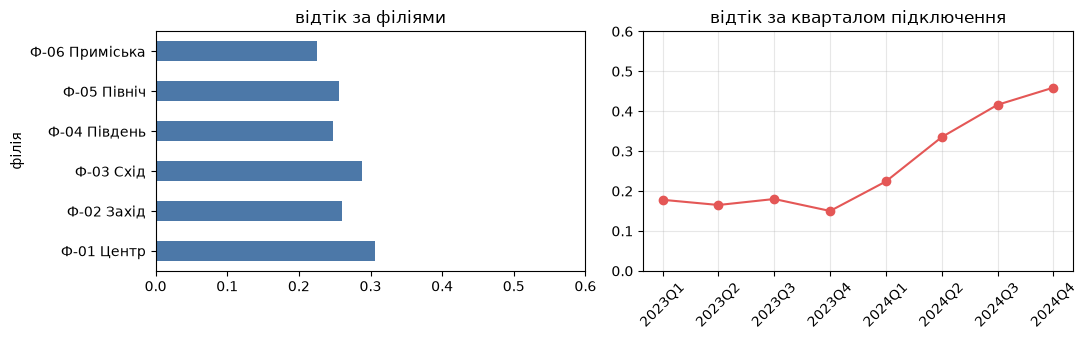

In [19]:
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній)
by_branch = (raw.groupby('філія')[TARGET].agg(['mean', 'count'])
                .rename(columns={'mean': 'частка відтоку', 'count': 'клієнтів'})
                .round(3))
display(by_branch)
print('розмах між філіями: від %.3f до %.3f (різниця %.3f)'
      % (by_branch['частка відтоку'].min(), by_branch['частка відтоку'].max(),
         by_branch['частка відтоку'].max() - by_branch['частка відтоку'].min()))

# 2) частка відтоку по кварталах дати підключення
conn = pd.to_datetime(raw['дата_підключення'], errors='coerce')
by_quarter = (raw.groupby(conn.dt.to_period('Q'))[TARGET].agg(['mean', 'count'])
                 .rename(columns={'mean': 'частка відтоку', 'count': 'клієнтів'})
                 .round(3))
display(by_quarter)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
by_branch['частка відтоку'].plot.barh(ax=ax[0], color='#4c78a8')
ax[0].set_title('відтік за філіями'); ax[0].set_xlim(0, 0.6)
x = range(len(by_quarter))
ax[1].plot(x, by_quarter['частка відтоку'].values, marker='o', color='#e45756')
ax[1].set_xticks(x)
ax[1].set_xticklabels([str(q) for q in by_quarter.index], rotation=45)
ax[1].grid(alpha=0.3)
ax[1].set_title('відтік за кварталом підключення'); ax[1].set_ylim(0, 0.6)
plt.tight_layout(); plt.show()

# Висновок: між філіями розкид невеликий (≈0.23–0.31) і плавний, жодної філії-«аномалії» немає.
# За датою — сходинка: до 2024Q1 відтік ≈ 15–18 %, далі різко росте до 46 % (злам близько березня 2024).


### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [20]:
SUSPECT = 'дата_підключення'  
assert SUSPECT in ('філія', 'дата_підключення')
BREAK_DATE = pd.Timestamp('2024-03-01')

source = (pd.to_datetime(raw['дата_підключення'], errors='coerce') >= BREAK_DATE).astype(int)
print('частка клієнтів після зламу: %.3f' % source.mean())
print('відтік до зламу: %.3f, після зламу: %.3f'
      % (y[source == 0].mean(), y[source == 1].mean()))

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))


частка клієнтів після зламу: 0.425
відтік до зламу: 0.164, після зламу: 0.400
ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.807
ті самі ознаки передбачають ВІДТІК  : AUC 0.828 ± 0.021


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [21]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.954
2. мінус цільовий витік,22,0.944
3. мінус оцінки людини,21,0.859
4. мінус артефакт збору,20,0.828


чесне число: 0.828 ± 0.021


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [22]:
DECISION_ARTEFACT = 'викинути'    
DECISION_WHY = ('Дата підключення монотонна: у момент прогнозу новий клієнт завжди «пізніший» за всіх, кого '
                'модель бачила, тож вона екстраполює «що новіший, то ризиковіший» на значення поза навчальним '
                'діапазоном, і ця закономірність (відтік 16 % до березня 2024 і 40 % після) не обов\'язково '
                'буде чинною далі. Залишати її — значить вчити модель розпізнавати період, а не клієнта: '
                'чесні ознаки передбачають «підключений після зламу» з AUC ≈ 0,81, тобто склад клієнтів '
                'справді змінився (більше оптики й автоплатежу). Тому викидаю стовпець із моделі (AUC відтоку '
                'падає з 0,859 до ≈0,828), але стрибок відтоку після березня 2024 окремо передаю маркетингу '
                'як бізнес-знахідку, яку треба з\'ясувати (нові умови, конкуренція чи інше правило обліку).')
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)


викинути — Дата підключення монотонна: у момент прогнозу новий клієнт завжди «пізніший» за всіх, кого модель бачила, тож вона екстраполює «що новіший, то ризиковіший» на значення поза навчальним діапазоном, і ця закономірність (відтік 16 % до березня 2024 і 40 % після) не обов'язково буде чинною далі. Залишати її — значить вчити модель розпізнавати період, а не клієнта: чесні ознаки передбачають «підключений після зламу» з AUC ≈ 0,81, тобто склад клієнтів справді змінився (більше оптики й автоплатежу). Тому викидаю стовпець із моделі (AUC відтоку падає з 0,859 до ≈0,828), але стрибок відтоку після березня 2024 окремо передаю маркетингу як бізнес-знахідку, яку треба з'ясувати (нові умови, конкуренція чи інше правило обліку).


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [ ]:
MODELS = {
    'логістична регресія':  logreg(),
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                                   random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                           max_iter=200, random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round(time.time() - t0, 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [ ]:
def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)
    n = len(d)
    h = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
    return float(d.mean()), float(h)

base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))


випадковий ліс         проти логістичної: -0.0137 ± 0.0102   значуще
гістограмний бустинг   проти логістичної: -0.0083 ± 0.0079   значуще


In [ ]:
CHOSEN_MODEL = 'логістична регресія'   
CHOSEN_WHY = ('Якість: AUC 0,828 ± 0,021 — найвище з чотирьох; парне порівняння показало, що ліс '
              '(−0,014 ± 0,010) і бустинг (−0,008 ± 0,008) не кращі, а трохи гірші за логістичну регресію, '
              'тобто складність нічого не дала. Стабільність: розкид згорток найменший (0,021 проти 0,028 у лісу). '
              'Швидкість: ≈1,6 с проти 14–19 с у лісу й бустингу. Інтерпретованість: коефіцієнти прямо '
              'показують напрямок впливу ознак, а це головна вимога задачі (пояснити, чому клієнт ризиковий).')
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)


обрано: логістична регресія — Якість: AUC 0,828 ± 0,021 — найвище з чотирьох; парне порівняння показало, що ліс (−0,014 ± 0,010) і бустинг (−0,008 ± 0,008) не кращі, а трохи гірші за логістичну регресію, тобто складність нічого не дала. Стабільність: розкид згорток найменший (0,021 проти 0,028 у лісу). Швидкість: ≈1,6 с проти 14–19 с у лісу й бустингу. Інтерпретованість: коефіцієнти прямо показують напрямок впливу ознак, а це головна вимога задачі (пояснити, чому клієнт ризиковий).


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [ ]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()

    # Гіпотеза 1: клієнт, який платить багато за одиницю швидкості, відчуває, що переплачує,
    # і радше піде до конкурента (платіж / швидкість тарифу).
    F['переплата_за_Мбіт'] = X['щомісячний_платіж'] / X['швидкість_тарифу_Мбіт']

    # Гіпотеза 2: найвразливіші — нові клієнти, які ще не «вросли» у послугу
    # (перші півроку договору).
    F['новачок_до_6м'] = (X['місяців_обслуговування'] <= 6).astype(float)


    # Гіпотеза 3: частота проблем, а не їхня кількість: два звернення за місяць і за п'ять років
    # означають різне (звернення на місяць обслуговування).
    F['звернень_на_місяць'] = (X['кількість_звернень_у_підтримку']
                               / X['місяців_обслуговування'].clip(lower=1))
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))


було 20 ознак, стало 23


In [ ]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.833 ± 0.022
приріст проти базового набору: +0.0043 ± 0.0022   значуще


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [ ]:
FEATURES_VS_MODEL = ('Нові ознаки дали значущий приріст AUC +0,0043 ± 0,0022 (0,828 → 0,833) майже безкоштовно: '
                     '≈1,7 с проти 1,6 с. Складніша модель на тих самих ознаках приросту не дала взагалі: бустинг '
                     '−0,008 ± 0,008, ліс −0,014 ± 0,010 проти логістичної, зате ціною 14–19 с замість 1,6 с '
                     '(у 9–12 разів довше). На розширеній матриці вони теж не наздоганяють: бустинг 0,823, ліс 0,819. '
                     'Отже, тут вигідніше додавати ознаки з розуміння предметної області, ніж ускладнювати модель; '
                     'але сам приріст малий (<0,01), тож головний результат — що чесна межа якості близько 0,83.')
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)


Нові ознаки дали значущий приріст AUC +0,0043 ± 0,0022 (0,828 → 0,833) майже безкоштовно: ≈1,7 с проти 1,6 с. Складніша модель на тих самих ознаках приросту не дала взагалі: бустинг −0,008 ± 0,008, ліс −0,014 ± 0,010 проти логістичної, зате ціною 14–19 с замість 1,6 с (у 9–12 разів довше). На розширеній матриці вони теж не наздоганяють: бустинг 0,823, ліс 0,819. Отже, тут вигідніше додавати ознаки з розуміння предметної області, ніж ускладнювати модель; але сам приріст малий (<0,01), тож головний результат — що чесна межа якості близько 0,83.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [ ]:
FINAL_X = X5                   
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.816
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

,вбудована важливість
номер_договору_серія,0.1109
річний_платіж,0.0869
щомісячний_платіж,0.0832
трафік_ГБ,0.0702
переплата_за_Мбіт,0.0678
місяців_обслуговування,0.0650
звернень_на_місяць,0.0589
вік,0.0550
швидкість_тарифу_Мбіт,0.0506
індекс_лояльності_CRM,0.0446


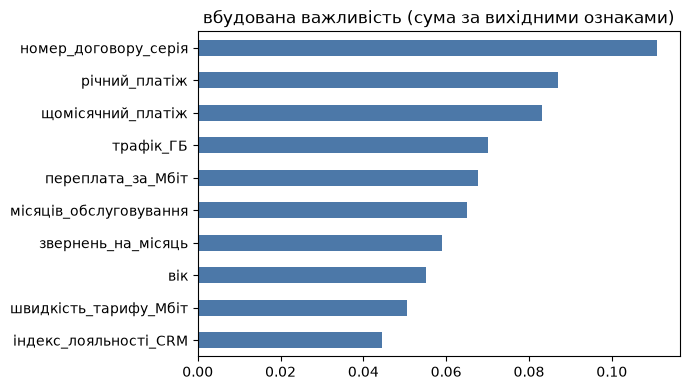

In [ ]:
prep_ = model.named_steps['prep']
names = prep_.get_feature_names_out()
raw_imp = pd.Series(model.named_steps['clf'].feature_importances_, index=names)
cat_cols_ = list(prep_.transformers_[1][2])     


def origin(n):
    """'cat__філія_ф-01 центр' -> 'філія'; 'num__вік' -> 'вік'."""
    kind, name = n.split('__', 1)
    if kind == 'cat':
        for c in cat_cols_:
            if name.startswith(c + '_'):
                return c
    return name


gini_imp = raw_imp.groupby([origin(n) for n in names]).sum().sort_values(ascending=False)
display(gini_imp.head(10).to_frame('вбудована важливість').round(4))

ax = gini_imp.head(10)[::-1].plot.barh(figsize=(7, 4), color='#4c78a8')
ax.set_title('вбудована важливість (сума за вихідними ознаками)')
plt.tight_layout(); plt.show()


### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [ ]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
трафік_ГБ,0.050995
місяців_обслуговування,0.035960
кількість_послуг,0.020957
вік,0.014302
річний_платіж,0.013225
щомісячний_платіж,0.011793
звернень_на_місяць,0.008397
автоплатіж,0.004914
аварій_на_ділянці_за_квартал,0.004626
тип_підключення,0.004379


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [ ]:
cmp_imp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp})
cmp_imp = cmp_imp.sort_values('вбудована', ascending=False)
cmp_imp['ранг_вбудованої'] = range(1, len(cmp_imp) + 1)
cmp_imp['ранг_перестановочної'] = cmp_imp['перестановочна'].rank(ascending=False).astype(int)
display(cmp_imp.head(10).round(4))


,вбудована,перестановочна,ранг_вбудованої,ранг_перестановочної
номер_договору_серія,0.1109,0.0001,1,18
річний_платіж,0.0869,0.0132,2,5
щомісячний_платіж,0.0832,0.0118,3,6
трафік_ГБ,0.0702,0.0510,4,1
переплата_за_Мбіт,0.0678,0.0028,5,11
місяців_обслуговування,0.0650,0.0360,6,2
звернень_на_місяць,0.0589,0.0084,7,7
вік,0.0550,0.0143,8,4
швидкість_тарифу_Мбіт,0.0506,-0.0009,9,19
індекс_лояльності_CRM,0.0446,0.0002,10,17


In [ ]:
FAKE_IMPORTANT = 'номер_договору_серія'   
FAKE_IMPORTANT_WHY = ('За вбудованою важливістю вона перша (0,111, ранг 1 із 23), а за перестановочною майже нуль '
                      '(0,0001, ранг 18). Вона має 55 різних значень, тож після кодування це 55 стовпців, і дерево '
                      'має безліч можливих розбиттів: майже завжди знаходить таке, що трохи зменшує неоднорідність '
                      'на навчальних даних, навіть коли зв\'язку з відтоком немає. На перевірковій частині '
                      'перемішування цієї ознаки якість не псує, отже вона нічого не пояснює.')
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)


хибно важлива ознака: номер_договору_серія


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [ ]:
num_ = FINAL_X.select_dtypes('number')
corr = num_.corr()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
pairs = pairs[pairs.abs() > 0.9].sort_values(key=abs, ascending=False)
display(pairs.to_frame('r').round(4))


,,r
щомісячний_платіж,річний_платіж,0.9991


In [ ]:
DUP_PAIR = ['щомісячний_платіж', 'річний_платіж']       
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

from sklearn.base import clone
X_nodup = FINAL_X.drop(columns=[DUP_PAIR[1]])
model_nd = make_pipe(X_nodup, clone(FINAL_CLF)).fit(Xtr.drop(columns=[DUP_PAIR[1]]), ytr)
perm_nd = permutation_importance(model_nd, Xte.drop(columns=[DUP_PAIR[1]]), yte, n_repeats=10,
                                 random_state=SEED, scoring='roc_auc')
perm_nd_imp = pd.Series(perm_nd.importances_mean, index=X_nodup.columns)
print('після видалення %s:' % DUP_PAIR[1])
print('   %-28s %+.4f' % (DUP_PAIR[0], perm_nd_imp[DUP_PAIR[0]]))


у повній моделі:
   щомісячний_платіж            +0.0118
   річний_платіж                +0.0132
після видалення річний_платіж:
   щомісячний_платіж            +0.0280


In [ ]:
DUP_EXPLANATION = ('Пара щомісячний_платіж і річний_платіж (r = 0,9991): річний платіж — це приблизно 12 щомісячних. '
                   'У повній моделі їхня перестановочна важливість лише 0,0118 і 0,0132: перемішуючи одну колонку, '
                   'ми нічого не ламаємо, бо лісу вистачає другої. Після видалення річного_платежу важливість '
                   'щомісячного зросла до 0,0280 (було 0,0118): тепер він єдиний носій інформації про платіж. '
                   'Отже, значення поодинці применшені дублюванням, а не відсутністю сигналу. Це не вада методу, а '
                   'точна відповідь на питання «що буде без цієї колонки», вада в інтерпретації «важливість мала, '
                   'отже ознаку можна викинути». (0,0280 навіть більше за суму обох у повній моделі, 0,025: '
                   'поодинці кожна з пари недооцінена.)')
assert DUP_EXPLANATION
print(DUP_EXPLANATION)


Пара щомісячний_платіж і річний_платіж (r = 0,9991): річний платіж — це приблизно 12 щомісячних. У повній моделі їхня перестановочна важливість лише 0,0118 і 0,0132: перемішуючи одну колонку, ми нічого не ламаємо, бо лісу вистачає другої. Після видалення річного_платежу важливість щомісячного зросла до 0,0280 (було 0,0118): тепер він єдиний носій інформації про платіж. Отже, значення поодинці применшені дублюванням, а не відсутністю сигналу. Це не вада методу, а точна відповідь на питання «що буде без цієї колонки», вада в інтерпретації «важливість мала, отже ознаку можна викинути». (0,0280 навіть більше за суму обох у повній моделі, 0,025: поодинці кожна з пари недооцінена.)


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

три найважливіші числові ознаки без пропусків: ['місяців_обслуговування', 'кількість_послуг', 'вік']


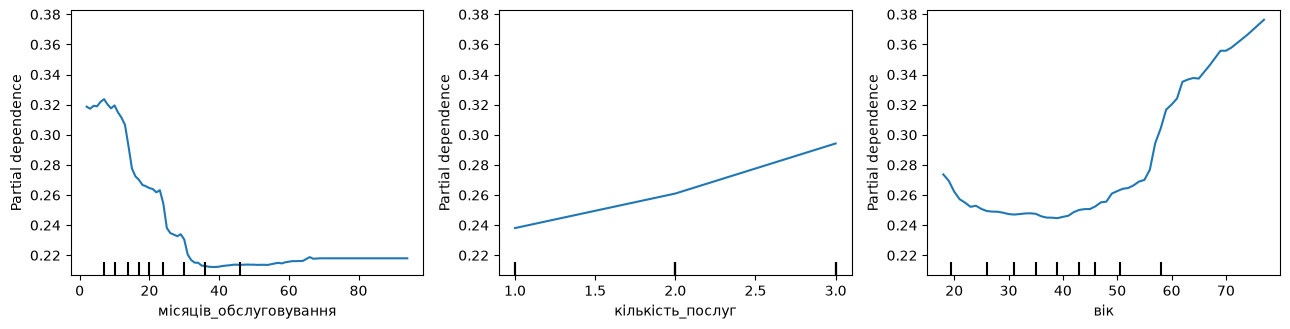

In [ ]:
from sklearn.inspection import PartialDependenceDisplay

num_cols_ = FINAL_X.select_dtypes('number').columns
no_nan = [c for c in perm_imp.index if c in num_cols_ and not FINAL_X[c].isna().any()]
top3_num = no_nan[:3]
print('три найважливіші числові ознаки без пропусків:', top3_num)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
PartialDependenceDisplay.from_estimator(model, Xte, features=top3_num, kind='average', ax=ax)
plt.tight_layout(); plt.show()

# Що означають криві:
# * місяців_обслуговування: ризик ≈ 0,32 у перші ~10 місяців, різко спадає до ≈ 0,21 до 35-го місяця
#   і далі лежить рівно: найвразливіші нові клієнти, а після трьох років стаж уже не додає лояльності;
# * кількість_послуг: майже пряма лінія вгору від 0,24 (1 послуга) до 0,29 (3 послуги);
# * вік: U-подібна крива: ≈ 0,27 у 18 років, мінімум ≈ 0,245 між 30 і 40 роками, після 55 різкий ріст
#   до ≈ 0,32 у 60 і ≈ 0,38 у найстарших: ризикованіші і наймолодші, і особливо найстарші клієнти.


### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

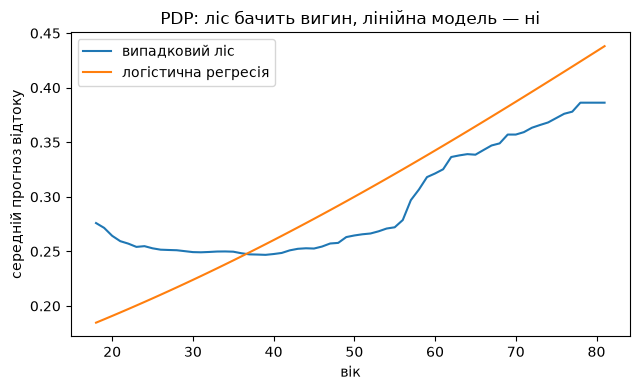

In [ ]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

lin = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)


def pdp_curve(m, data, col):
    r = partial_dependence(m, data, [col], kind='average')
    grid = r['grid_values'][0] if 'grid_values' in r else r['values'][0]
    return np.asarray(grid), np.asarray(r['average'][0])


fig, ax = plt.subplots(figsize=(6.5, 4))
for lab, m_ in [('випадковий ліс', model), ('логістична регресія', lin)]:
    gx, gy = pdp_curve(m_, FINAL_X, NONLINEAR_FEATURE)
    ax.plot(gx, gy, label=lab)
ax.set_xlabel(NONLINEAR_FEATURE); ax.set_ylabel('середній прогноз відтоку')
ax.set_title('PDP: ліс бачить вигин, лінійна модель — ні'); ax.legend()
plt.tight_layout(); plt.show()


In [ ]:
NONLINEAR_MEANING = ('Вік: ризик мінімальний близько 39 років (≈0,247 за PDP) і зростає в обидва боки: до ≈0,28 у 18-річних '
                     'і до ≈0,32–0,36 у 60–70 років. Емпірично відтік: 30 % у віці 17–25, 20 % у 32–40, 31 % у 50–60, '
                     '38,5 % у 60–70. Змістовно: молоді часто змінюють провайдера, з\'їжджають чи економлять, а люди '
                     'старшого віку рідше освоюють послугу й чутливіші до ціни (це гіпотеза, дані причин не дають).')
NONLINEAR_FIX = ('Квадрат відхилення від оптимуму: (вік − 39)². Лінійна модель сама цього не побачить, бо може лише '
                 'зростати або спадати; з ознакою AUC логістичної регресії зріс на +0,0093 ± 0,0027 (значуще).')
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)


Вік: ризик мінімальний близько 39 років (≈0,247 за PDP) і зростає в обидва боки: до ≈0,28 у 18-річних і до ≈0,32–0,36 у 60–70 років. Емпірично відтік: 30 % у віці 17–25, 20 % у 32–40, 31 % у 50–60, 38,5 % у 60–70. Змістовно: молоді часто змінюють провайдера, з'їжджають чи економлять, а люди старшого віку рідше освоюють послугу й чутливіші до ціни (це гіпотеза, дані причин не дають).
Квадрат відхилення від оптимуму: (вік − 39)². Лінійна модель сама цього не побачить, бо може лише зростати або спадати; з ознакою AUC логістичної регресії зріс на +0,0093 ± 0,0027 (значуще).


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [ ]:
gx, gy = pdp_curve(model, FINAL_X, NONLINEAR_FEATURE)
x0 = float(gx[np.argmin(gy)])
print('мінімум ризику при %s ≈ %.1f' % (NONLINEAR_FEATURE, x0))

X6 = X5.copy()
X6['відхилення_від_оптимуму_кв'] = (X6[NONLINEAR_FEATURE] - x0) ** 2

auc6 = cross_val_score(make_pipe(X6, logreg()), X6, y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(auc5, auc6)
print('без ознаки: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('з ознакою : AUC %.3f ± %.3f' % (auc6.mean(), auc6.std()))
print('приріст   : %+0.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))



мінімум ризику при вік ≈ 39.0
без ознаки: AUC 0.833 ± 0.022
з ознакою : AUC 0.842 ± 0.021
приріст   : +0.0093 ± 0.0027   значуще


In [ ]:
QUAD_GAIN = m_q   
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)


приріст від сконструйованої ознаки: +0.0093


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

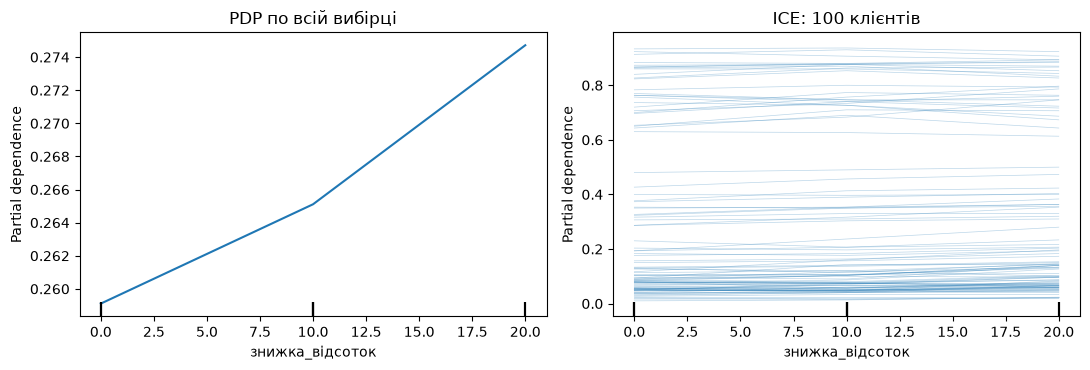

In [ ]:
disc = 'знижка_відсоток'
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
PartialDependenceDisplay.from_estimator(model, FINAL_X, [disc], kind='average', ax=ax[0])
ax[0].set_title('PDP по всій вибірці')
PartialDependenceDisplay.from_estimator(model, FINAL_X, [disc], kind='individual',
                                        subsample=100, random_state=SEED, ax=ax[1])
ax[1].set_title('ICE: 100 клієнтів')
plt.tight_layout(); plt.show()


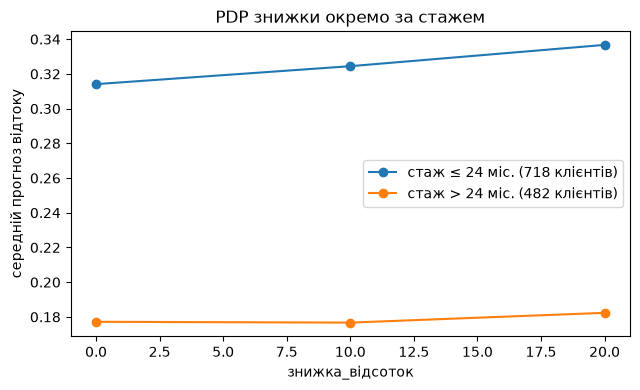

In [ ]:
short = FINAL_X['місяців_обслуговування'] <= 24
fig, ax = plt.subplots(figsize=(6.5, 4))
for lab, mask in [('стаж ≤ 24 міс. (%d клієнтів)' % short.sum(), short),
                  ('стаж > 24 міс. (%d клієнтів)' % (~short).sum(), ~short)]:
    gx, gy = pdp_curve(model, FINAL_X[mask], disc)
    ax.plot(gx, gy, marker='o', label=lab)
ax.set_xlabel(disc); ax.set_ylabel('середній прогноз відтоку')
ax.set_title('PDP знижки окремо за стажем'); ax.legend()
plt.tight_layout(); plt.show()


### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [ ]:
grp = pd.Series(np.where(short, 'до 24 міс.', 'понад 24 міс.'), index=FINAL_X.index, name='стаж')
emp = (pd.DataFrame({'знижка': FINAL_X[disc], 'стаж': grp, 'відтік': y})
         .pivot_table(index='знижка', columns='стаж', values='відтік', aggfunc=['mean', 'count']))
emp.columns = ['%s: %s' % ({'mean': 'частка відтоку', 'count': 'клієнтів'}[a], b) for a, b in emp.columns]
display(emp.round(3))


,частка відтоку: до 24 міс.,частка відтоку: понад 24 міс.,клієнтів: до 24 міс.,клієнтів: понад 24 міс.
знижка,,,,
0.0,0.278,0.207,291,184
10.0,0.347,0.133,245,165
20.0,0.445,0.075,182,133


In [ ]:
INTERACTION_FOUND = ('Знижка діє у протилежні боки. У клієнтів зі стажем до 24 місяців відтік із ростом знижки '
                     'росте: 27,8 % (без знижки) → 34,7 % (10 %) → 44,5 % (20 %). У клієнтів понад 24 місяці він падає: '
                     '20,7 % → 13,3 % → 7,5 %. У середньому ефекти гасяться, тому звичайний PDP майже плаский '
                     '(≈0,26 → 0,28), а ICE і PDP по групах показують справжню картину.')
BUSINESS_ACTION = ('Знижку варто пропонувати лояльним клієнтам зі стажем понад 24 місяці: у них вона супроводжується '
                   'найменшим відтоком. Новим клієнтам її не роздавати автоматично: у них знижка стоїть поруч '
                   'із високим відтоком (імовірно, вона вже видається тим, хто збирається піти, тож це не доводить '
                   'шкоди від неї). Перш ніж змінювати політику, перевірити на контрольованому експерименті: '
                   'це спостережні дані.')
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)


Знижка діє у протилежні боки. У клієнтів зі стажем до 24 місяців відтік із ростом знижки росте: 27,8 % (без знижки) → 34,7 % (10 %) → 44,5 % (20 %). У клієнтів понад 24 місяці він падає: 20,7 % → 13,3 % → 7,5 %. У середньому ефекти гасяться, тому звичайний PDP майже плаский (≈0,26 → 0,28), а ICE і PDP по групах показують справжню картину.
Знижку варто пропонувати лояльним клієнтам зі стажем понад 24 місяці: у них вона супроводжується найменшим відтоком. Новим клієнтам її не роздавати автоматично: у них знижка стоїть поруч із високим відтоком (імовірно, вона вже видається тим, хто збирається піти, тож це не доводить шкоди від неї). Перш ніж змінювати політику, перевірити на контрольованому експерименті: це спостережні дані.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [ ]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])     
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
sv1 = sv[..., 1] if (hasattr(sv, 'ndim') and sv.ndim == 3) else sv
print('матриця значень Шеплі:', np.shape(sv1))

матриця значень Шеплі: (300, 96)


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

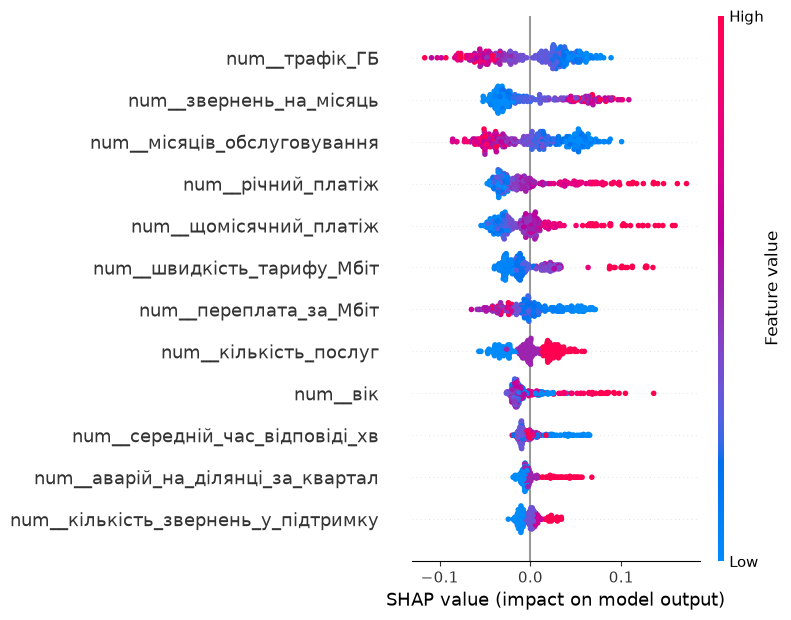

In [ ]:
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names, max_display=12, show=False)
plt.tight_layout(); plt.show()

# Що видно на графіку:
# * напрям: для місяців_обслуговування і трафік_ГБ червоні точки (високі значення) ліворуч, тобто знижують ризик,
#   а сині (низькі) праворуч: чим більший стаж і трафік, тим менший ризик. Для платежів і швидкості тарифу
#   навпаки: високі значення (червоні) праворуч, підвищують ризик.
# * однаковість: у платежів, стажу і трафіку кольори чітко розділені, напрям один для всіх клієнтів.
#   А в «вік» і сині, і червоні точки праворуч від нуля: напрям не однаковий, залежить від значення
#   (молоді й старі ризикованіші), що збігається з U-подібним PDP із розділу 10.


### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

In [ ]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

contrib = pd.Series(sv1[idx], index=[origin(n) for n in feat_names]).groupby(level=0).sum()
top3_c = contrib.reindex(contrib.abs().sort_values(ascending=False).index)[:3]
for f, v in top3_c.items():
    print('%-32s внесок %+.3f   значення у клієнта: %s' % (f, v, Xte.iloc[idx][f]))
print('базовий рівень %.3f, сума внесків %+.3f' % (np.ravel(expl.expected_value)[-1], contrib.sum()))


ризик клієнта: 0.850
річний_платіж                    внесок +0.147   значення у клієнта: 6962.8
щомісячний_платіж                внесок +0.141   значення у клієнта: 590.55
швидкість_тарифу_Мбіт            внесок +0.112   значення у клієнта: 1000.0
базовий рівень 0.264, сума внесків +0.586


In [ ]:
EXPLANATION_FOR_MANAGER = ('Клієнт платить за зв\'язок дуже багато: майже 591 грн на місяць (майже 7 тис. на рік; дорожче платять '
                           'лише близько 3 % клієнтів) '
                           'за найшвидший тариф на 1 Гбіт/с. Саме висока вартість разом із дорогим швидким тарифом '
                           'найсильніше підвищує ймовірність того, що він піде: ризик оцінено в 85 % при звичайних '
                           'для клієнтів 26 %. Дві з трьох причин по суті одна й та сама: загальна ціна послуги.')
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)


Клієнт платить за зв'язок дуже багато: майже 591 грн на місяць (майже 7 тис. на рік; дорожче платять лише близько 3 % клієнтів) за найшвидший тариф на 1 Гбіт/с. Саме висока вартість разом із дорогим швидким тарифом найсильніше підвищує ймовірність того, що він піде: ризик оцінено в 85 % при звичайних для клієнтів 26 %. Дві з трьох причин по суті одна й та сама: загальна ціна послуги.


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [ ]:
SHAP_NOT_CAUSAL_FEATURE = 'трафік_ГБ'
SHAP_NOT_CAUSAL_WHY = ('Низький трафік має великий внесок у ризик (перша за величиною ознака на графіку), але це '
                       'наслідок, а не причина: клієнт, який вже збирається піти, менше користується послугою. '
                       'Якщо «змінити» трафік (подарувати ГБ чи нав\'язати користування), причина відходу '
                       '(ціна, умови, конкурент) нікуди не зникне. Значення Шеплі показують, що модель трафіком '
                       'користується, а не що клієнт лишиться, якщо трафік збільшити. Те саме і зі стажем: '
                       'великий внесок, а вплинути на нього неможливо.')
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)


трафік_ГБ — Низький трафік має великий внесок у ризик (перша за величиною ознака на графіку), але це наслідок, а не причина: клієнт, який вже збирається піти, менше користується послугою. Якщо «змінити» трафік (подарувати ГБ чи нав'язати користування), причина відходу (ціна, умови, конкурент) нікуди не зникне. Значення Шеплі показують, що модель трафіком користується, а не що клієнт лишиться, якщо трафік збільшити. Те саме і зі стажем: великий внесок, а вплинути на нього неможливо.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [ ]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",номер_договору_серія,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",щомісячний_платіж + річний_платіж,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",трафік_ГБ,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [ ]:
FIFTH_MISTAKE = ('Власна ознака «звернень на місяць» (звернення / місяці стажу) у значеннях Шеплі друга за внеском, '
                 'і її легко прочитати як «клієнт часто скаржиться — покращимо підтримку». Але знаменник робить її '
                 'частково ознакою стажу: одне звернення за перший місяць дає 1,0, а за два роки 0,04. Серед 10 % '
                 'клієнтів із найвищим значенням 37 % новачків до 6 місяців (серед решти 3 %), медіанний стаж 7 міс. '
                 'проти 22. У новачків вона майже нічого не розрізняє: відтік 34 % при високій частоті і 35 % при '
                 'низькій; ефект є лише у давніших клієнтів (понад 24 міс.: 9 % → 22 %). Тож великий внесок у нового '
                 'клієнта означає здебільшого «новий», а не «незадоволений підтримкою». Перевірка: дивитися ознаку '
                 'окремо за групами стажу або залежність значень Шеплі від стажу.')
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)


Власна ознака «звернень на місяць» (звернення / місяці стажу) у значеннях Шеплі друга за внеском, і її легко прочитати як «клієнт часто скаржиться — покращимо підтримку». Але знаменник робить її частково ознакою стажу: одне звернення за перший місяць дає 1,0, а за два роки 0,04. Серед 10 % клієнтів із найвищим значенням 37 % новачків до 6 місяців (серед решти 3 %), медіанний стаж 7 міс. проти 22. У новачків вона майже нічого не розрізняє: відтік 34 % при високій частоті і 35 % при низькій; ефект є лише у давніших клієнтів (понад 24 міс.: 9 % → 22 %). Тож великий внесок у нового клієнта означає здебільшого «новий», а не «незадоволений підтримкою». Перевірка: дивитися ознаку окремо за групами стажу або залежність значень Шеплі від стажу.


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [ ]:
TOP_N = 100
proba = model.predict_proba(Xte)[:, 1]
top = np.argsort(-proba)[:TOP_N]
hit = int(yte.iloc[top].sum())
base_rate = float(yte.mean())
lift = (hit / TOP_N) / base_rate
print('у топ-%d справді пішли: %d (%.0f %%)' % (TOP_N, hit, 100 * hit / TOP_N))
print('навмання очікували б:  %.0f (%.0f %%)' % (TOP_N * base_rate, 100 * base_rate))
print('lift = %.2f' % lift)
print('AUC на цій самій відкладеній частині: %.3f' % auc_hold)


у топ-100 справді пішли: 54 (54 %)
навмання очікували б:  26 (26 %)
lift = 2.05
AUC на цій самій відкладеній частині: 0.816


In [ ]:
LIFT_MEANING = ('Серед 100 клієнтів із найвищим ризиком справді пішли 54, а випадковий вибір дав би 26: у 2,05 раза '
                'більше «влучань», тобто обдзвін за списком у два з лишком рази результативніший за обдзвін навмання.')
assert LIFT_MEANING
print(LIFT_MEANING)


Серед 100 клієнтів із найвищим ризиком справді пішли 54, а випадковий вибір дав би 26: у 2,05 раза більше «влучань», тобто обдзвін за списком у два з лишком рази результативніший за обдзвін навмання.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [ ]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_09.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [ ]:
REPORT = '''
1. Метрика — AUC: відтік рідкісний (26,4 %), а точність приховує це: модель «ніхто не піде» дала б 73,6 % точності
   при нульовій користі. AUC оцінює ранжування клієнтів незалежно від порога.
2. Викинуто: id_клієнта (ідентифікатор, лише запам'ятовується); дата_розірвання і сума_повернення_депозиту
   (з'являються після розірвання договору); кількість_дзвінків_утримання (відділ утримання дзвонить після сигналу
   про ризик); дата_підключення (артефакт збору). Детектор з 5.1 не знайшов кількість_дзвінків_утримання:
   поле заповнене в усіх рядках, пропусків немає, а детектор дивиться лише на заповненість.
3. Чесне число: AUC 0,828 ± 0,021 (було 0,954 до чистки). Різниця між моделями у 0,004 при розкиді 0,021 нічого не
   означає: потрібне парне порівняння по згортках.
4. Так: відтік стрибає з 16,4 % до 40,0 % для клієнтів, підключених після березня 2024. AUC передбачення джерела
   0,807. За філіями розкид малий (22,6–30,6 %), артефакт у часі, а не в філіях: у нову когорту чи інший період
   моделі довіряти не можна без перевірки.
5. Нові ознаки: +0,0043 ± 0,0022 (значуще), ≈1,7 с. Складніша модель: бустинг −0,0083 ± 0,0079 (≈19 с),
   ліс −0,0137 ± 0,0102 (≈14 с), тобто гірші за логістичну регресію. Ознаки вигідніші.
6. номер_договору_серія: ранг 1 за вбудованою (0,111), ранг 18 за перестановочною (0,0001). Дерева обирають розбиття
   серед усіх порогів, а ознака з 55 значеннями дає їх найбільше, тож майже завжди знаходить «корисне» розбиття.
7. Пара щомісячний_платіж / річний_платіж (r = 0,9991): у повній моделі 0,0118 і 0,0132, після видалення річного
   щомісячний зріс до 0,0280. Перемішування однієї колонки компенсує друга: метод чесно відповідає, що буде «без
   цієї колонки», а не «чи несе вона сигнал».
8. Вік: мінімум ризику ≈ 39 років, вище в молодих і особливо в старших. Логістична регресія цього не бачить
   (може лише зростати або спадати); з ознакою (вік − 39)² приріст AUC +0,0093 ± 0,0027.
9. PDP знижки плаский (≈0,26 → 0,28), але до 24 міс. стажу відтік росте 27,8 → 34,7 → 44,5 %, а після 24 міс.
   падає 20,7 → 13,3 → 7,5 %. ICE і PDP по групах показали різноспрямовані ефекти, що гасяться при усередненні.
10. трафік_ГБ: великий внесок, але низький трафік це наслідок наміру піти, а не причина. «Модель цим користується»
    не означає «зміна цієї ознаки утримає клієнта»: причинності в даних немає.
11. За списком із 100 клієнтів lift = 2,05 (54 справжні відтоки проти 26 навмання; AUC на цій відкладеній
    частині 0,816). Застереження: оцінка на одній відкладеній вибірці з 360 клієнтів має широкий розкид, а після
    березня 2024 склад клієнтів змінився, тож для нових когорт показники треба перевіряти знову.

Декларація про використання ШІ: для написання коду комірок і чернеток відповідей використано ШІ-асистента
(Claude Code). Що саме перевірено самостійно: написаний код, числа у відповідях, переписано чернетки.
'''
print(REPORT)



1. Метрика — AUC: відтік рідкісний (26,4 %), а точність приховує це: модель «ніхто не піде» дала б 73,6 % точності
   при нульовій користі. AUC оцінює ранжування клієнтів незалежно від порога.
2. Викинуто: id_клієнта (ідентифікатор, лише запам'ятовується); дата_розірвання і сума_повернення_депозиту
   (з'являються після розірвання договору); кількість_дзвінків_утримання (відділ утримання дзвонить після сигналу
   про ризик); дата_підключення (артефакт збору). Детектор з 5.1 не знайшов кількість_дзвінків_утримання:
   поле заповнене в усіх рядках, пропусків немає, а детектор дивиться лише на заповненість.
3. Чесне число: AUC 0,828 ± 0,021 (було 0,954 до чистки). Різниця між моделями у 0,004 при розкиді 0,021 нічого не
   означає: потрібне парне порівняння по згортках.
4. Так: відтік стрибає з 16,4 % до 40,0 % для клієнтів, підключених після березня 2024. AUC передбачення джерела
   0,807. За філіями розкид малий (22,6–30,6 %), артефакт у часі, а не в філіях: у нову когорту чи інший пер

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.